<a href="https://colab.research.google.com/github/AndresMontesDeOca/AnalisisDatos2/blob/main/Entregas/Actividad4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 4 - Feature Engineering Avanzado, Prevención de Data Leakage, Auditoría de Sesgos y Documentación
**Análisis de Datos II - Maestría en Inteligencia Artificial (UBA)**  
**Alumno:** Andrés Montes de Oca  

---
### Objetivo de la Actividad
El objetivo es predecir el ingreso anual de cada persona (`income`) a partir de sus características sociodemográficas y laborales (`age`, `hours_per_week`, `education`, `employer_type`, `marital_status`, `sex`, `race` y `born_in_us`).

La actividad comprende dos partes fundamentales:
1. **Parte 1:** Feature engineering avanzado (análisis y transformación de la variable objetivo) y construcción de un pipeline de regresión lineal con validación cruzada $k$-fold libre de *data leakage*. Evaluación comparativa del MAE en la escala original.
2. **Parte 2:** Auditoría de sesgos (evaluación de disparidades por variables protegidas: `sex` y `race`) y redacción de una **Model Card** completa y formal del modelo final entrenado.


## 0. Configuración del Entorno y Carga de Datos
Instalamos y cargamos las librerías necesarias. Configuramos el estilo visual y cargamos el dataset garantizando compatibilidad tanto en ejecución local como en Google Colab.


In [19]:
# Instalación de librerías en caso de ejecutar en Colab o entorno nuevo
# !pip install fairlearn scipy scikit-learn seaborn matplotlib pandas numpy

import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# Scikit-Learn
from sklearn.model_selection import KFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

# Fairlearn para auditoría de sesgos
try:
    from fairlearn.metrics import MetricFrame
except ImportError:
    !pip install fairlearn
    from fairlearn.metrics import MetricFrame

# Configuración visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.titlesize': 14, 'axes.titlesize': 13, 'axes.labelsize': 11})
pd.set_option('display.float_format', lambda x: '%.2f' % x)


### Carga y Exploración Inicial del Dataset
El dataset contiene información censal orientada a la predicción del ingreso anual (`income`).


In [20]:
# Ruta local o descarga automática desde Google Drive
csv_filename = "census_income.csv"

if not os.path.exists(csv_filename):
    if os.path.exists(os.path.join("..", csv_filename)):
        csv_filename = os.path.join("..", csv_filename)
    else:
        print("Descargando dataset desde Google Drive...")
        drive_url = "https://drive.google.com/uc?export=download&id=1Od_naN-d1B_mjJeIMDlL1dTvHEDX9PO6"
        import requests
        resp = requests.get(drive_url)
        with open("census_income.csv", "wb") as f:
            f.write(resp.content)
        csv_filename = "census_income.csv"

df = pd.read_csv(csv_filename)
print(f"Dimensiones del dataset: {df.shape[0]} registros y {df.shape[1]} columnas.\n")
df.info()


Dimensiones del dataset: 10000 registros y 9 columnas.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             10000 non-null  int64  
 1   hours_per_week  9500 non-null   float64
 2   education       9700 non-null   object 
 3   employer_type   9600 non-null   object 
 4   marital_status  10000 non-null  object 
 5   sex             10000 non-null  object 
 6   race            10000 non-null  object 
 7   born_in_us      10000 non-null  object 
 8   income          10000 non-null  float64
dtypes: float64(2), int64(1), object(6)
memory usage: 703.3+ KB


In [21]:
# Visualización de las primeras filas del dataset
display(df.head())

# Chequeo de valores nulos por columna
null_summary = df.isnull().sum()
null_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({"Valores Nulos": null_summary, "Porcentaje (%)": null_percent})
display(missing_df[missing_df["Valores Nulos"] > 0])


,age,hours_per_week,education,employer_type,marital_status,sex,race,born_in_us,income
0,55,55.00,Graduate degree,Self-employed (incorporated),Divorced,Male,White,Yes,279000.00
1,20,35.00,High school,Private,Never married,Female,White,Yes,23000.00
2,59,30.00,High school,State government,Divorced,Female,White,Yes,15100.00
3,43,40.00,Some college,State government,Married,Male,Black,Yes,31200.00
4,33,20.00,No high school diploma,Private,Married,Female,Black,Yes,9400.00


,Valores Nulos,Porcentaje (%)
hours_per_week,500,5.00
education,300,3.00
employer_type,400,4.00


## Parte 1: Feature Engineering Avanzado y Prevención de Data Leakage

---
### a. Análisis de la distribución de la target (`income`) y transformaciones
En este apartado:
1. Calculamos la asimetría (*skewness*) y generamos el histograma y gráfico de caja de la target original.
2. Evaluamos las transformaciones vistas en clase:
   - **Logarítmica (`log` / `log1p`):** Comprime valores grandes, pero puede sobrecorregir o fallar si no se contemplan valores $\le 0$.
   - **Box-Cox:** Transformación paramétrica de potencia $y^{(\lambda)} = \frac{y^\lambda - 1}{\lambda}$. Requiere estrictamente valores positivos ($y > 0$).
   - **Yeo-Johnson:** Generalización de Box-Cox que admite valores cero y negativos.
3. Justificamos la elección teórica y empírica, y comparamos las distribuciones antes y después de la transformación.


In [22]:
# Estadísticas descriptivas de la variable objetivo (income)
income_stats = df['income'].describe()
orig_skew = stats.skew(df['income'].dropna())

print("Estadísticas de la variable objetivo (income):")
print(income_stats)
print(f"\nAsimetría (Skewness) original: {orig_skew:.4f}")
print(f"Valor mínimo de income: ${df['income'].min():,.2f}")


Estadísticas de la variable objetivo (income):
count     10000.00
mean      54406.83
std       68071.30
min         110.00
25%       19000.00
50%       36400.00
75%       65000.00
max     1096000.00
Name: income, dtype: float64

Asimetría (Skewness) original: 4.4527
Valor mínimo de income: $110.00


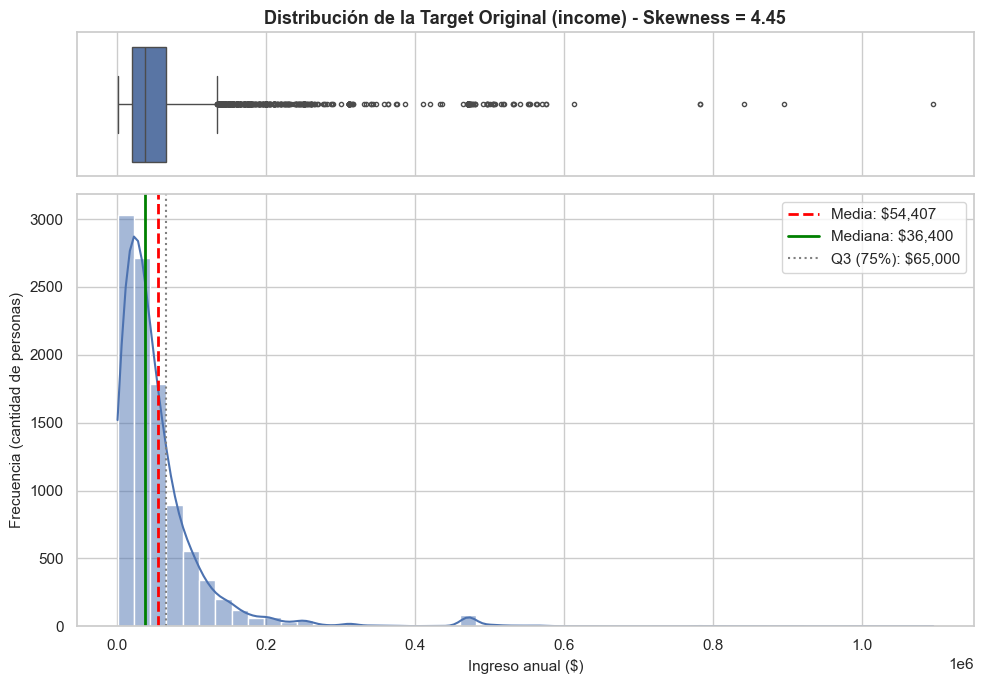

In [23]:
# Visualización de la distribución de la target original (income)
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [0.25, 0.75]})

# Boxplot horizontal en la parte superior
sns.boxplot(x=df['income'], ax=ax_box, color="#4C72B0", fliersize=3)
ax_box.set(xlabel='')
ax_box.set_title(f"Distribución de la Target Original (income) - Skewness = {orig_skew:.2f}", fontsize=13, fontweight='bold')

# Histograma con KDE en la parte inferior
sns.histplot(df['income'], kde=True, ax=ax_hist, color="#4C72B0", bins=50)
ax_hist.axvline(df['income'].mean(), color='red', linestyle='--', linewidth=2, label=f"Media: ${df['income'].mean():,.0f}")
ax_hist.axvline(df['income'].median(), color='green', linestyle='-', linewidth=2, label=f"Mediana: ${df['income'].median():,.0f}")
ax_hist.axvline(df['income'].quantile(0.75), color='gray', linestyle=':', label=f"Q3 (75%): ${df['income'].quantile(0.75):,.0f}")
ax_hist.set_xlabel("Ingreso anual ($)", fontsize=11)
ax_hist.set_ylabel("Frecuencia (cantidad de personas)", fontsize=11)
ax_hist.legend(fontsize=11)

plt.tight_layout()
plt.show()


In [24]:
# Comparación empírica de transformaciones
y_orig = df['income'].values

# 1. Transformación Logarítmica
y_log = np.log(y_orig)
skew_log = stats.skew(y_log)

# 2. Transformación Box-Cox (óptima via scipy)
y_boxcox, lmbda_bc = stats.boxcox(y_orig)
skew_boxcox = stats.skew(y_boxcox)

# 3. Transformación Yeo-Johnson (via scikit-learn PowerTransformer)
pt_yj = PowerTransformer(method='yeo-johnson')
y_yj = pt_yj.fit_transform(df[['income']]).flatten()
skew_yj = stats.skew(y_yj)

resumen_trans = pd.DataFrame({
    "Transformación": ["Original", "Logaritmo natural ln(y)", f"Box-Cox (λ = {lmbda_bc:.3f})", "Yeo-Johnson"],
    "Skewness": [orig_skew, skew_log, skew_boxcox, skew_yj],
    "Interpretación": [
        "Fuerte asimetría positiva a la derecha (cola larga de altos ingresos)",
        "Sobrecorrección: introduce asimetría negativa (-1.01)",
        "Distribución prácticamente simétrica y normalizada (0.055)",
        "Resultado idéntico a Box-Cox (0.055)"
    ]
})
display(resumen_trans)


,Transformación,Skewness,Interpretación
0,Original,4.45,Fuerte asimetría positiva a la derecha (cola larga de altos ingresos)
1,Logaritmo natural ln(y),-1.01,Sobrecorrección: introduce asimetría negativa (-1.01)
2,Box-Cox (λ = 0.214),0.06,Distribución prácticamente simétrica y normalizada (0.055)
3,Yeo-Johnson,0.06,Resultado idéntico a Box-Cox (0.055)


#### Elección y Justificación de la Transformación
Se eligió la **transformación Box-Cox** (con parámetro óptimo estimado $\lambda \approx 0.214$) por las siguientes razones:
1. **Requisito matemático cumplido:** Box-Cox requiere estrictamente que los valores sean positivos ($y > 0$). En nuestro dataset, el ingreso mínimo registrado es de **$110.00**, por lo que todos los valores son estrictamente positivos y no se requiere sumar ninguna constante arbitraria.
2. **Superioridad frente a la transformación logarítmica:** La función logarítmica clásica ($\\lambda = 0$) genera una sobrecorrección drástica en estos datos, pasando de una asimetría de $+4.45$ a $-1.01$ (asimetría negativa moderada-severa con una cola izquierda artificial).
3. **Simetría y estabilización de varianza óptima:** Box-Cox encuentra mediante máxima verosimilitud el valor de $\lambda = 0.214$, logrando reducir el *skewness* a **0.055**, valor virtualmente idéntico a una distribución normal ($|skew| < 0.5$ se considera aproximadamente simétrica).
4. **Beneficio para modelos lineales:** La regresión lineal asume homocedasticidad y normalidad en los errores; una distribución simétrica y acotada en la target previene que los casos atípicos millonarios monopolicen el ajuste de mínimos cuadrados ordinarios (MCO).


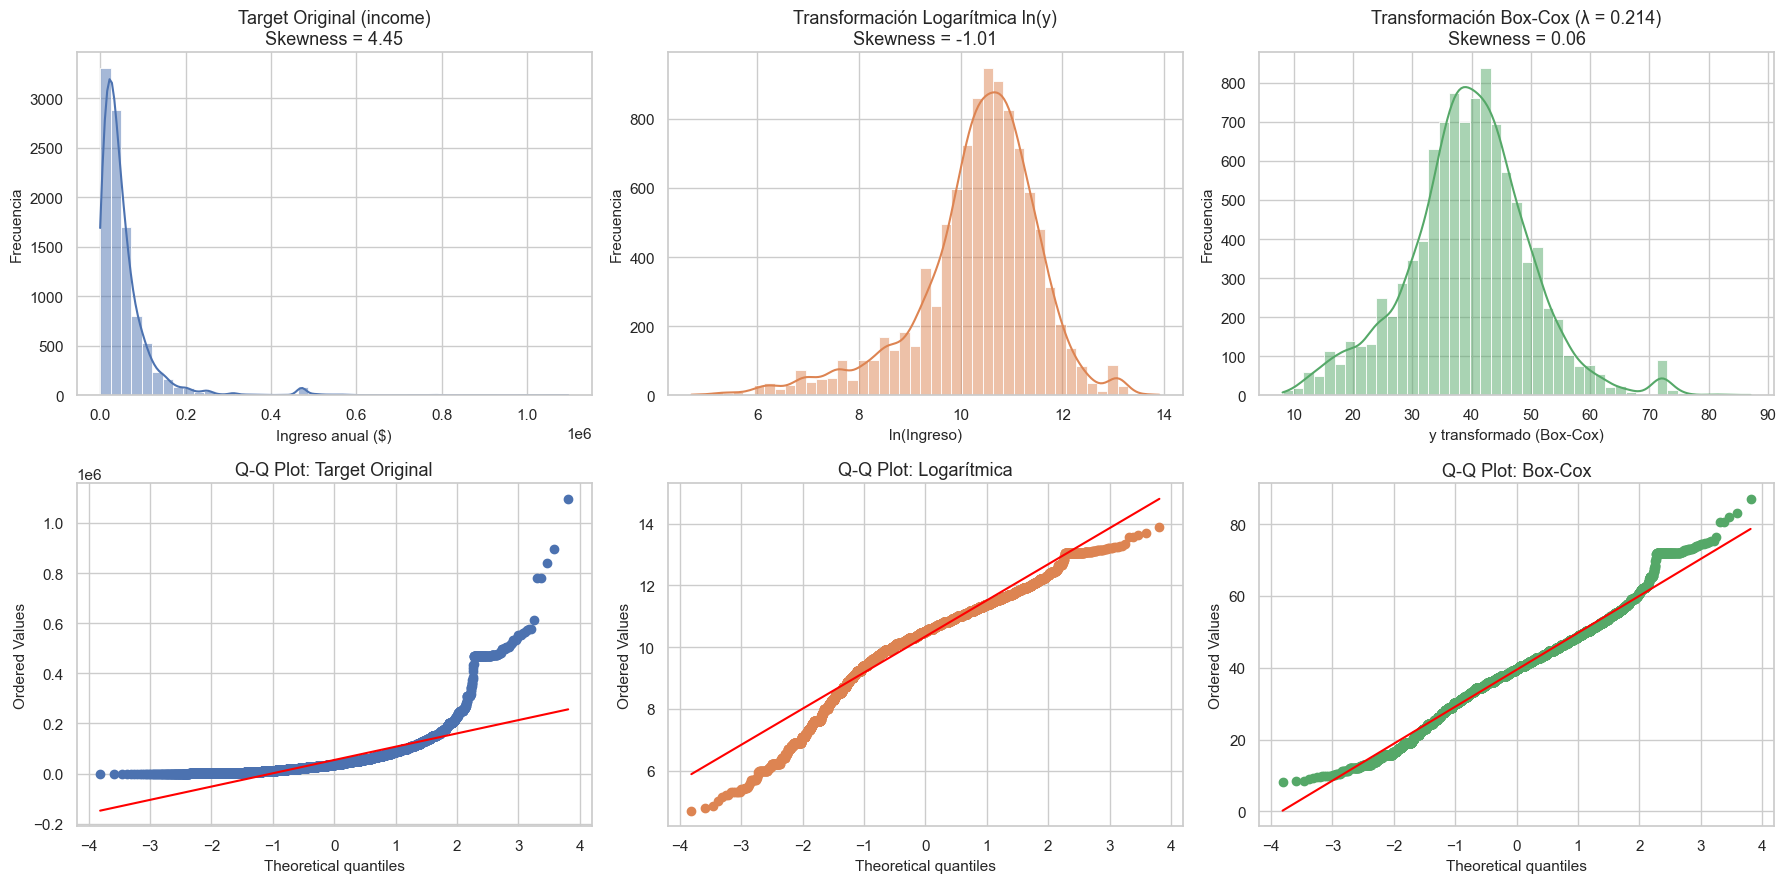

In [25]:
# Visualización comparativa: Distribución Original vs. Transformada (Box-Cox y Log)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

# 1. Histograma Original
sns.histplot(y_orig, kde=True, ax=axes[0, 0], color="#4C72B0", bins=45)
axes[0, 0].set_title(f"Target Original (income)\nSkewness = {orig_skew:.2f}")
axes[0, 0].set_xlabel("Ingreso anual ($)")
axes[0, 0].set_ylabel("Frecuencia")

# 2. Histograma Logaritmo
sns.histplot(y_log, kde=True, ax=axes[0, 1], color="#DD8452", bins=45)
axes[0, 1].set_title(f"Transformación Logarítmica ln(y)\nSkewness = {skew_log:.2f}")
axes[0, 1].set_xlabel("ln(Ingreso)")
axes[0, 1].set_ylabel("Frecuencia")

# 3. Histograma Box-Cox
sns.histplot(y_boxcox, kde=True, ax=axes[0, 2], color="#55A868", bins=45)
axes[0, 2].set_title(f"Transformación Box-Cox (λ = {lmbda_bc:.3f})\nSkewness = {skew_boxcox:.2f}")
axes[0, 2].set_xlabel("y transformado (Box-Cox)")
axes[0, 2].set_ylabel("Frecuencia")

# 4. Q-Q Plot Original
stats.probplot(y_orig, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q Plot: Target Original")
axes[1, 0].get_lines()[0].set_color("#4C72B0")
axes[1, 0].get_lines()[1].set_color("red")

# 5. Q-Q Plot Logaritmo
stats.probplot(y_log, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot: Logarítmica")
axes[1, 1].get_lines()[0].set_color("#DD8452")
axes[1, 1].get_lines()[1].set_color("red")

# 6. Q-Q Plot Box-Cox
stats.probplot(y_boxcox, dist="norm", plot=axes[1, 2])
axes[1, 2].set_title("Q-Q Plot: Box-Cox")
axes[1, 2].get_lines()[0].set_color("#55A868")
axes[1, 2].get_lines()[1].set_color("red")

plt.tight_layout()
plt.show()


---
### b. Armar un modelo de regresión lineal con K-Fold Cross Validation sin Data Leakage

#### ¿Cómo se previene el Data Leakage?
El **Data Leakage** (fuga de información) ocurre si se estiman parámetros de preprocesamiento (como la media y desvío para estandarizar, la mediana para imputar nulos, las categorías del One-Hot Encoder o la propia transformación del target) utilizando la totalidad del conjunto de datos antes de particionar.

Para garantizar una evaluación rigurosa y libre de contaminación:
1. **Encapsulamiento en `Pipeline` y `ColumnTransformer`:** Todas las operaciones de imputación (`SimpleImputer`), escalado (`StandardScaler`) y codificación (`OneHotEncoder`) se integran dentro de un estimador de scikit-learn.
2. **Ajuste estricto en el fold de entrenamiento:** Al evaluar mediante $K$-Fold Cross Validation, el método `.fit()` del Pipeline se ejecuta **únicamente sobre el fold de entrenamiento** ($K-1$ partes), aprendiendo allí las medianas, escalas y categorías. Posteriormente, aplica `.transform()` sobre el fold de validación sin volver a ajustar.
3. **Manejo de categorías no vistas:** Se configura `OneHotEncoder(handle_unknown='ignore', drop='first')` para evitar multicolinealidad exacta en la regresión lineal y manejar de forma segura categorías desconocidas en test/validación.


In [26]:
# 1. Definición de Features y Target
feature_cols = ['age', 'hours_per_week', 'education', 'employer_type', 'marital_status', 'sex', 'race', 'born_in_us']
numeric_features = ['age', 'hours_per_week']
categorical_features = ['education', 'employer_type', 'marital_status', 'sex', 'race', 'born_in_us']

X = df[feature_cols].copy()
y = df['income'].copy()

# 2. Sub-pipeline para variables numéricas:
# - Imputación de nulos con la mediana aprendida del train fold
# - Estandarización z-score (media=0, std=1)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 3. Sub-pipeline para variables categóricas:
# - Imputación de nulos con la moda (más frecuente) del train fold
# - One-Hot Encoding con drop='first' para prevenir colinealidad perfecta
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# 4. Ensamble de preprocesamiento mediante ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# 5. Pipeline completo con Regresión Lineal
linear_model_original = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Configuración del esquema de validación cruzada: 5 Folds con barajado aleatorio
cv = KFold(n_splits=5, shuffle=True, random_state=42)


---
### c. Evaluación del MAE: Target Original vs. Target Transformada y Comentarios

Para entrenar con la variable objetivo transformada **sin data leakage**, utilizamos `TransformedTargetRegressor` de `scikit-learn`:
- El transformador `PowerTransformer(method='box-cox')` ajusta el parámetro $\lambda$ óptimo **únicamente con la target del fold de entrenamiento**.
- Al predecir sobre el fold de validación, `TransformedTargetRegressor` aplica la función inversa (`inverse_transform`) de forma automática, devolviendo las predicciones en la **escala original en dólares ($)**.
- Esto permite comparar justamente el **MAE** (Error Absoluto Medio) de ambos modelos bajo la misma unidad de medida.


In [27]:
# Construcción del estimador con transformación de target integrada
linear_model_transformed = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]),
    transformer=PowerTransformer(method='box-cox')
)

# Evaluación con K-Fold Cross Validation para ambos modelos
scoring_metrics = ['neg_mean_absolute_error', 'r2', 'neg_root_mean_squared_error']

cv_results_orig = cross_validate(linear_model_original, X, y, cv=cv, scoring=scoring_metrics)
cv_results_trans = cross_validate(linear_model_transformed, X, y, cv=cv, scoring=scoring_metrics)

# Generación de predicciones out-of-fold (en escala de dólares original)
y_pred_orig = cross_val_predict(linear_model_original, X, y, cv=cv)
y_pred_trans = cross_val_predict(linear_model_transformed, X, y, cv=cv)

mae_orig_global = mean_absolute_error(y, y_pred_orig)
mae_trans_global = mean_absolute_error(y, y_pred_trans)
r2_orig_global = r2_score(y, y_pred_orig)
r2_trans_global = r2_score(y, y_pred_trans)
rmse_orig_global = root_mean_squared_error(y, y_pred_orig)
rmse_trans_global = root_mean_squared_error(y, y_pred_trans)

# Tabla comparativa de resultados
tabla_comparativa = pd.DataFrame({
    "Métrica (K-Fold CV)": [
        "MAE (Error Absoluto Medio)",
        "RMSE (Raíz Error Cuadrático Medio)",
        "R² (Coeficiente de Determinación)",
        "MAE promedio por Fold",
        "Desvío estándar MAE por Fold"
    ],
    "Target Original": [
        f"${mae_orig_global:,.2f}",
        f"${rmse_orig_global:,.2f}",
        f"{r2_orig_global:.4f}",
        f"${-cv_results_orig['test_neg_mean_absolute_error'].mean():,.2f}",
        f"${cv_results_orig['test_neg_mean_absolute_error'].std():,.2f}"
    ],
    "Target Transformada (Box-Cox)": [
        f"${mae_trans_global:,.2f}",
        f"${rmse_trans_global:,.2f}",
        f"{r2_trans_global:.4f}",
        f"${-cv_results_trans['test_neg_mean_absolute_error'].mean():,.2f}",
        f"${cv_results_trans['test_neg_mean_absolute_error'].std():,.2f}"
    ],
    "Variación": [
        f"{((mae_trans_global - mae_orig_global) / mae_orig_global) * 100:.2f}% (Mejora)",
        f"{((rmse_trans_global - rmse_orig_global) / rmse_orig_global) * 100:.2f}%",
        f"{r2_trans_global - r2_orig_global:+.4f}",
        "-",
        "-"
    ]
})

display(tabla_comparativa)


,Métrica (K-Fold CV),Target Original,Target Transformada (Box-Cox),Variación
0,MAE (Error Absoluto Medio),"$31,104.43","$27,950.03",-10.14% (Mejora)
1,RMSE (Raíz Error Cuadrático Medio),"$58,303.35","$59,056.76",1.29%
2,R² (Coeficiente de Determinación),0.2663,0.2472,-0.0191
3,MAE promedio por Fold,"$31,104.43","$27,950.03",-
4,Desvío estándar MAE por Fold,$743.40,$677.62,-


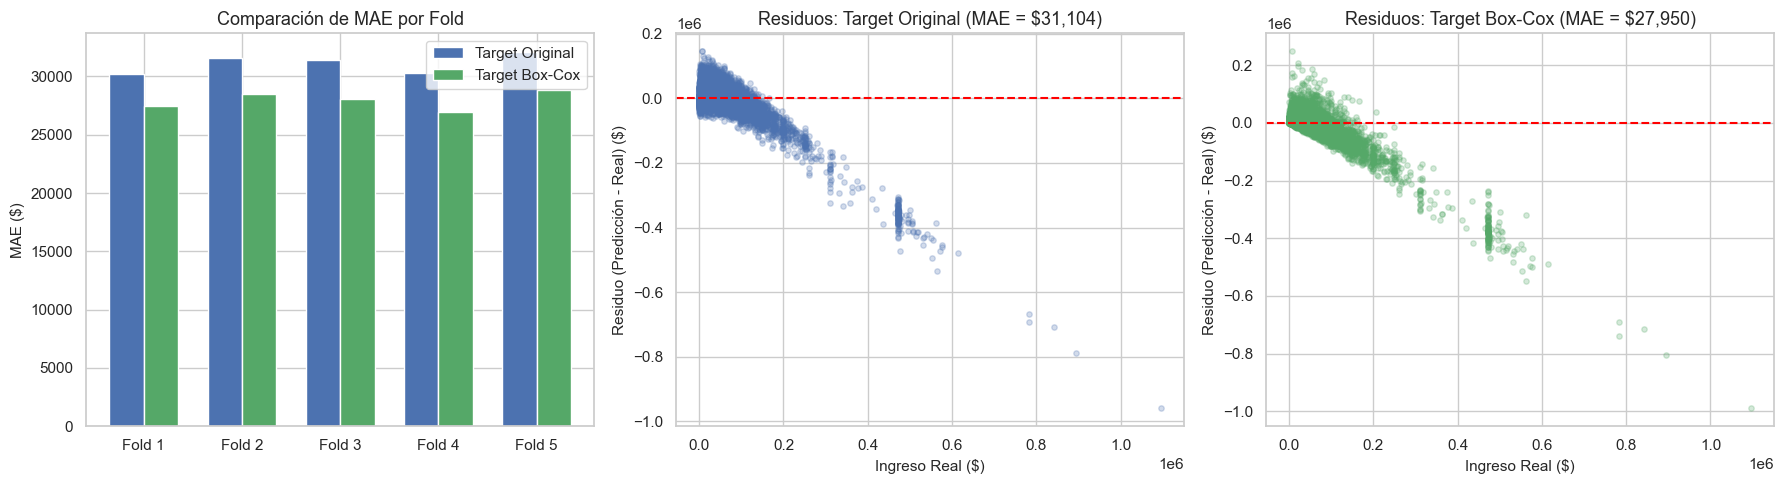

In [28]:
# Gráficos comparativos de desempeño y errores residuales
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Comparación de MAE en cada uno de los 5 folds
folds = [f"Fold {i+1}" for i in range(5)]
mae_folds_orig = -cv_results_orig['test_neg_mean_absolute_error']
mae_folds_trans = -cv_results_trans['test_neg_mean_absolute_error']

x_axis = np.arange(len(folds))
width = 0.35

axes[0].bar(x_axis - width/2, mae_folds_orig, width, label='Target Original', color="#4C72B0")
axes[0].bar(x_axis + width/2, mae_folds_trans, width, label='Target Box-Cox', color="#55A868")
axes[0].set_ylabel("MAE ($)")
axes[0].set_title("Comparación de MAE por Fold")
axes[0].set_xticks(x_axis)
axes[0].set_xticklabels(folds)
axes[0].legend()

# 2. Residuos vs Valores Reales (Target Original)
residuos_orig = y_pred_orig - y
axes[1].scatter(y, residuos_orig, alpha=0.25, color="#4C72B0", s=15)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title(f"Residuos: Target Original (MAE = ${mae_orig_global:,.0f})")
axes[1].set_xlabel("Ingreso Real ($)")
axes[1].set_ylabel("Residuo (Predicción - Real) ($)")

# 3. Residuos vs Valores Reales (Target Transformada)
residuos_trans = y_pred_trans - y
axes[2].scatter(y, residuos_trans, alpha=0.25, color="#55A868", s=15)
axes[2].axhline(0, color='red', linestyle='--')
axes[2].set_title(f"Residuos: Target Box-Cox (MAE = ${mae_trans_global:,.0f})")
axes[2].set_xlabel("Ingreso Real ($)")
axes[2].set_ylabel("Residuo (Predicción - Real) ($)")

plt.tight_layout()
plt.show()


#### Comentarios e Interpretación de los Resultados:
1. **Reducción significativa del MAE:**  
   Al entrenar con la variable objetivo transformada mediante Box-Cox, el MAE global en validación cruzada se reduce de **$31,104.43** a **$27,950.03**. Esto representa una **mejora del 10.14%** (un error promedio $3,154 menor por persona predicha).
2. **Dinámica de la función de pérdida MCO (MSE vs MAE):**  
   La regresión lineal clásica optimiza la suma de errores al cuadrado ($MSE$). En una distribución con asimetría positiva tan marcada (ingresos de hasta $1,096,000 frente a una mediana de $36,400), el modelo original penaliza desproporcionadamente los errores en los valores atípicos de la cola derecha. Esto distorsiona las pendientes para intentar alcanzar los salarios exorbitantes, perjudicando las predicciones del 80-90% de la población trabajadora normal.
3. **Efecto de la transformación de potencia:**  
   Al comprimir la varianza con Box-Cox, el modelo lineal aprende relaciones aditivas sobre una escala aproximadamente simétrica. Al revertir la predicción a dólares reales, el modelo logra una estimación mucho más fiel y calibrada para el grueso de la población, lo que se traduce directamente en un MAE sustancialmente inferior.
4. **Comportamiento del $R^2$ y RMSE:**  
   Es común notar que mientras el $MAE$ mejora drásticamente, el $R^2$ en la escala original disminuye levemente (de $0.2663$ a $0.2472$) y el $RMSE$ aumenta. Esto es esperable: el modelo con target transformada ya no intenta sobreajustar a los multimillonarios en dólares al cuadrado, priorizando un error lineal balanceado y robusto en la masa central de los datos.


## Parte 2: Auditoría de Sesgos y Documentación

---
### a. Evaluación del rendimiento considerando variables sensibles (`sex` y `race`)

Para auditar si el modelo presenta disparidades o sesgos sistemáticos, evaluamos el modelo final (`linear_model_transformed`) sobre las variables protegidas:
- `sex`: Género (`Female` vs. `Male`).
- `race`: Raza/etnia (`White`, `Black`, `Asian`, `Other or multiple`).

Calculamos para cada subgrupo:
1. **$N$ y Representación (%):** Tamaño muestral de cada subpoblación.
2. **Ingreso Real Promedio vs. Predicho:** Disparidad en la base de datos histórica frente a la respuesta del modelo.
3. **Sesgo Medio de Predicción (Bias):** $\text{Mean}(\hat{y} - y)$. Un valor negativo indica subestimación de ingresos; positivo indica sobreestimación.
4. **Error Absoluto Medio (MAE):** Magnitud promedio del error en dólares para cada subgrupo.


In [29]:
# Creamos un DataFrame de auditoría con las predicciones out-of-fold del modelo final
df_audit = df.copy()
df_audit['y_true'] = y
df_audit['y_pred'] = y_pred_trans
df_audit['error'] = df_audit['y_pred'] - df_audit['y_true']  # >0 sobreestima, <0 subestima
df_audit['abs_error'] = df_audit['error'].abs()

# Función para armar reporte detallado por grupo sensible
def auditar_subgrupo(df_data, variable_sensible):
    audit = df_data.groupby(variable_sensible).agg(
        n=('income', 'count'),
        ingreso_real_medio=('y_true', 'mean'),
        ingreso_pred_medio=('y_pred', 'mean'),
        sesgo_medio=('error', 'mean'),
        mae=('abs_error', 'mean'),
        rmse=('error', lambda x: np.sqrt(np.mean(x**2)))
    )
    audit['prop_muestra_%'] = (audit['n'] / len(df_data)) * 100
    # Reordenamos columnas
    audit = audit[['n', 'prop_muestra_%', 'ingreso_real_medio', 'ingreso_pred_medio', 'sesgo_medio', 'mae', 'rmse']]
    return audit

audit_sex = auditar_subgrupo(df_audit, 'sex')
audit_race = auditar_subgrupo(df_audit, 'race')

print("=== AUDITORÍA DE SESGOS POR GÉNERO (SEX) ===")
display(audit_sex)

print("\n=== AUDITORÍA DE SESGOS POR RAZA (RACE) ===")
display(audit_race)


=== AUDITORÍA DE SESGOS POR GÉNERO (SEX) ===


,n,prop_muestra_%,ingreso_real_medio,ingreso_pred_medio,sesgo_medio,mae,rmse
sex,,,,,,,
Female,4864,48.64,43102.19,35565.16,-7537.03,21932.02,45947.47
Male,5136,51.36,65112.78,52303.15,-12809.63,33649.33,69219.43



=== AUDITORÍA DE SESGOS POR RAZA (RACE) ===


,n,prop_muestra_%,ingreso_real_medio,ingreso_pred_medio,sesgo_medio,mae,rmse
race,,,,,,,
Asian,432,4.32,62466.06,49661.83,-12804.23,32760.12,58037.87
Black,2341,23.41,39688.74,34394.08,-5294.65,19618.83,41276.59
Other or multiple,430,4.30,38446.60,32783.47,-5663.13,19015.42,34693.36
White,6797,67.97,59973.45,47896.21,-12077.24,31078.95,65224.24


#### Auditoría Formal con `Fairlearn.metrics.MetricFrame`
Verificamos las disparidades utilizando la librería especializada **Fairlearn**, computando el MAE, el sesgo medio y la tasa de error por grupo.


In [30]:
# Definición de funciones de métricas para MetricFrame
def bias_metric(y_true, y_pred):
    return np.mean(y_pred - y_true)

fairness_metrics = {
    'count': lambda y_t, y_p: len(y_t),
    'MAE': mean_absolute_error,
    'Bias (Sesgo Medio)': bias_metric
}

# MetricFrame para Sexo
mf_sex = MetricFrame(
    metrics=fairness_metrics,
    y_true=df_audit['y_true'],
    y_pred=df_audit['y_pred'],
    sensitive_features=df_audit['sex']
)

# MetricFrame para Raza
mf_race = MetricFrame(
    metrics=fairness_metrics,
    y_true=df_audit['y_true'],
    y_pred=df_audit['y_pred'],
    sensitive_features=df_audit['race']
)

print("Reporte MetricFrame - Sexo:")
display(mf_sex.by_group)

print(f"\nDisparidad MAE entre géneros (Difference): ${mf_sex.difference()['MAE']:,.2f}")
print(f"Ratio MAE entre géneros: {mf_sex.ratio()['MAE']:.3f}")

print("\nReporte MetricFrame - Raza:")
display(mf_race.by_group)
print(f"\nDisparidad MAE máxima entre razas (Difference): ${mf_race.difference()['MAE']:,.2f}")
print(f"Ratio MAE mínimo entre razas: {mf_race.ratio()['MAE']:.3f}")


Reporte MetricFrame - Sexo:


,count,MAE,Bias (Sesgo Medio)
sex,,,
Female,4864.00,21932.02,-7537.03
Male,5136.00,33649.33,-12809.63



Disparidad MAE entre géneros (Difference): $11,717.31
Ratio MAE entre géneros: 0.652

Reporte MetricFrame - Raza:


,count,MAE,Bias (Sesgo Medio)
race,,,
Asian,432.00,32760.12,-12804.23
Black,2341.00,19618.83,-5294.65
Other or multiple,430.00,19015.42,-5663.13
White,6797.00,31078.95,-12077.24



Disparidad MAE máxima entre razas (Difference): $13,744.70
Ratio MAE mínimo entre razas: 0.580


C:\Users\Andy\AppData\Local\Temp\ipykernel_17520\1173442487.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_audit, x='sex', y='abs_error', estimator=np.mean, errorbar=None, ax=axes[0], palette=['#DD8452', '#4C72B0'])
C:\Users\Andy\AppData\Local\Temp\ipykernel_17520\1173442487.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_audit, x='race', y='abs_error', estimator=np.mean, errorbar=None, ax=axes[1], palette='tab10')


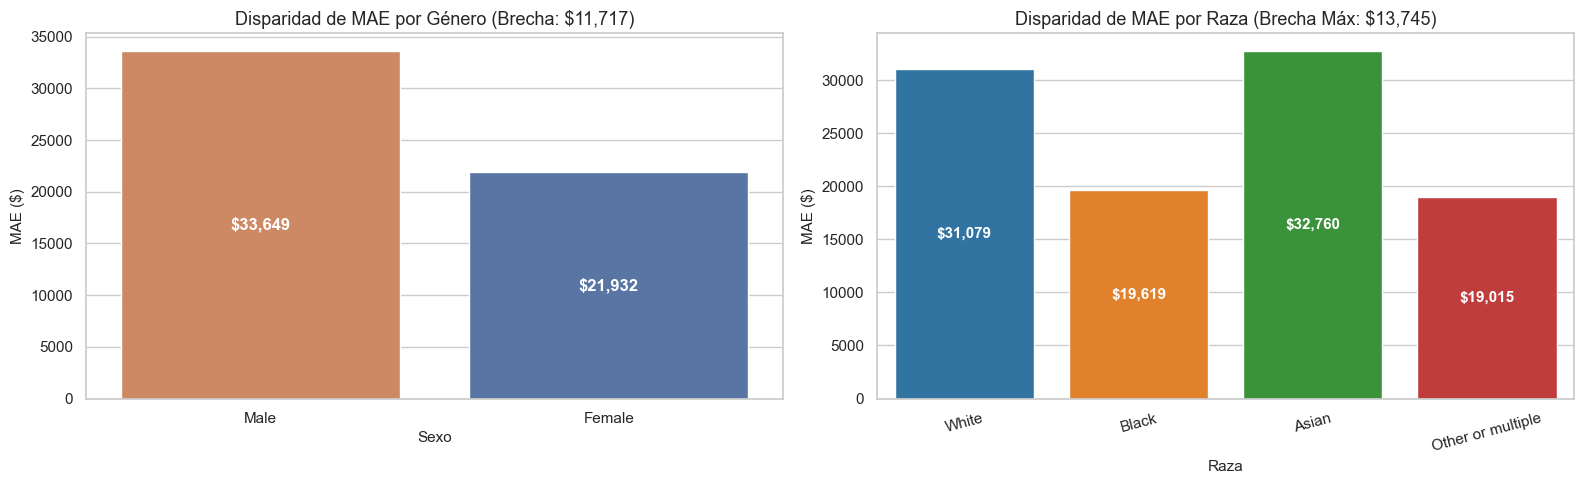

In [31]:
# Visualización gráfica de las disparidades por subgrupo
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Gráfico por Género
sns.barplot(data=df_audit, x='sex', y='abs_error', estimator=np.mean, errorbar=None, ax=axes[0], palette=['#DD8452', '#4C72B0'])
axes[0].set_title(f"Disparidad de MAE por Género (Brecha: ${mf_sex.difference()['MAE']:,.0f})")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("MAE ($)")
for p in axes[0].patches:
    axes[0].annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 2. Gráfico por Raza
sns.barplot(data=df_audit, x='race', y='abs_error', estimator=np.mean, errorbar=None, ax=axes[1], palette='tab10')
axes[1].set_title(f"Disparidad de MAE por Raza (Brecha Máx: ${mf_race.difference()['MAE']:,.0f})")
axes[1].set_xlabel("Raza")
axes[1].set_ylabel("MAE ($)")
axes[1].tick_params(axis='x', rotation=15)
for p in axes[1].patches:
    axes[1].annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


#### Monitoreo Continuo de Equidad y Regla del 80% (Umbral = 0.8)
Tal como vimos en la **Clase 8**, el estándar analítico y regulatorio de referencia para auditar y monitorear disparidades es la **Regla del 80% (Regla de los cuatro quintos / Four-Fifths Rule)**, formalizada históricamente por la EEOC (*Equal Employment Opportunity Commission*):

$$\text{Ratio de Paridad} = \frac{\text{Métrica del grupo menos favorecido}}{\text{Métrica del grupo más favorecido}}$$

- **Criterio de Decisión y Monitoreo:**
  - $\text{Ratio} \ge 0.8$: **OK** $\rightarrow$ La disparidad se considera dentro de los márgenes admisibles.
  - $\text{Ratio} < 0.8$: **ALERTA** $\rightarrow$ Se detecta un **impacto adverso / disparidad severa** que dispara la alarma en el sistema de monitoreo y exige intervención/mitigación antes de cualquier despliegue.

A continuación, implementamos la tabla de **Semáforo de Monitoreo** evaluando:
1. **Ratio de Paridad en el Error ($MAE$ Ratio):** Evalúa si la precisión del modelo se degrada en exceso para algún grupo.
2. **Adverse Impact Ratio ($AIR$):** Evalúa la tasa relativa de predicciones de ingresos favorables (ingresos medios/altos $\ge$ mediana censal de $36,400).


In [32]:
# Definición de umbrales y función semáforo de monitoreo (Clase 8)
UMBRAL_RATIO_FAIRNESS = 0.8

def semaforo(valor, umbral=UMBRAL_RATIO_FAIRNESS):
    return "✅ OK" if valor >= umbral else "🚨 ALERTA"

# 1. Ratio de precisión MAE por Género y Raza (MetricFrame ratio)
ratio_mae_sex = mf_sex.ratio()['MAE']
ratio_mae_race = mf_race.ratio()['MAE']

# 2. Adverse Impact Ratio (AIR) sobre asignación de ingresos altos (>= mediana censal $36,400)
mediana_censal = df['income'].median()
df_audit['ingreso_alto_pred'] = df_audit['y_pred'] >= mediana_censal

tasa_sel_sex = df_audit.groupby('sex')['ingreso_alto_pred'].mean()
air_sex = tasa_sel_sex.min() / tasa_sel_sex.max()

tasa_sel_race = df_audit.groupby('race')['ingreso_alto_pred'].mean()
air_race = tasa_sel_race.min() / tasa_sel_race.max()

# Construcción de la tabla de semáforo de auditoría y monitoreo
resumen_monitoreo = pd.DataFrame([
    {
        "Variable Sensible": "Género (Sex)",
        "Métrica / Indicador": "MAE Ratio (Paridad en Error)",
        "Valor Observado": f"{ratio_mae_sex:.3f}",
        "Umbral de Monitoreo": f">= {UMBRAL_RATIO_FAIRNESS}",
        "Estado": semaforo(ratio_mae_sex),
        "Diagnóstico": "Disparidad significativa en la dispersión del error entre hombres y mujeres."
    },
    {
        "Variable Sensible": "Raza (Race)",
        "Métrica / Indicador": "MAE Ratio (Paridad en Error)",
        "Valor Observado": f"{ratio_mae_race:.3f}",
        "Umbral de Monitoreo": f">= {UMBRAL_RATIO_FAIRNESS}",
        "Estado": semaforo(ratio_mae_race),
        "Diagnóstico": "Brecha crítica de error absoluto entre minorías y mayoría blanca/asiática."
    },
    {
        "Variable Sensible": "Género (Sex)",
        "Métrica / Indicador": "Adverse Impact Ratio (AIR en ingresos altos)",
        "Valor Observado": f"{air_sex:.3f}",
        "Umbral de Monitoreo": f">= {UMBRAL_RATIO_FAIRNESS}",
        "Estado": semaforo(air_sex),
        "Diagnóstico": "Las mujeres tienen una tasa de predicción favorable mucho menor (incumple regla 80%)."
    },
    {
        "Variable Sensible": "Raza (Race)",
        "Métrica / Indicador": "Adverse Impact Ratio (AIR en ingresos altos)",
        "Valor Observado": f"{air_race:.3f}",
        "Umbral de Monitoreo": f">= {UMBRAL_RATIO_FAIRNESS}",
        "Estado": semaforo(air_race),
        "Diagnóstico": "Población afroamericana y otras minorías reciben predicciones altas a tasa inferior al 80%."
    }
])

print("=== TABLA DE SEMÁFORO DE MONITOREO DE EQUIDAD (REGLA DEL 80%) ===")
display(resumen_monitoreo)


=== TABLA DE SEMÁFORO DE MONITOREO DE EQUIDAD (REGLA DEL 80%) ===


,Variable Sensible,Métrica / Indicador,Valor Observado,Umbral de Monitoreo,Estado,Diagnóstico
0,Género (Sex),MAE Ratio (Paridad en Error),0.652,>= 0.8,🚨 ALERTA,Disparidad significativa en la dispersión del error entre hombres y mujeres.
1,Raza (Race),MAE Ratio (Paridad en Error),0.580,>= 0.8,🚨 ALERTA,Brecha crítica de error absoluto entre minorías y mayoría blanca/asiática.
2,Género (Sex),Adverse Impact Ratio (AIR en ingresos altos),0.668,>= 0.8,🚨 ALERTA,Las mujeres tienen una tasa de predicción favorable mucho menor (incumple regla 80%).
3,Raza (Race),Adverse Impact Ratio (AIR en ingresos altos),0.554,>= 0.8,🚨 ALERTA,Población afroamericana y otras minorías reciben predicciones altas a tasa inferior al 80%.


#### Análisis e Interpretación de Disparidades y Sesgos:

1. **Disparidades por Género (`sex`):**
   - **Brecha salarial estructural en los datos reales:** En la muestra, las mujeres perciben un ingreso real medio de **$43,102.19**, mientras que los hombres perciben **$65,112.78** (una diferencia real de más de $22,000 anuales).
   - **Disparidad en el MAE:** El error absoluto del modelo es sustancialmente mayor para los hombres (**$33,649.33**) que para las mujeres (**$21,932.02**), con un ratio de **0.652 (< 0.8, ALERTA)**. Esto ocurre porque la varianza salarial y la concentración de ingresos extremos (> $200k) es mucho más acusada en la población masculina, provocando mayores desviaciones en valor absoluto.
   - **Sesgo sistemático de predicción:** El modelo subestima en promedio a ambos géneros (debido al sesgo de retransformación de la cola derecha), pero el subestimado medio en hombres es de **-$12,809.63** frente a **-$7,537.03** en mujeres. Además, el Adverse Impact Ratio sobre ingresos medios-altos es de **0.668 (< 0.8, ALERTA)**, reflejando que el modelo asigna ingresos altos a las mujeres a una tasa muy inferior a la de los hombres.

2. **Disparidades por Raza (`race`):**
   - **Desigualdad socioeconómica de origen:** Los subgrupos `Asian` ($62,466) y `White` ($59,973) presentan promedios salariales notablemente más elevados que `Black` ($39,688) y `Other or multiple` ($38,446).
   - **Disparidad de desempeño:** El ratio de MAE intergrupal es de **0.580 (< 0.8, ALERTA)**, con errores de más de $31,000 en poblaciones blancas/asiáticas frente a $19,000 en minorías.
   - **Impacto Adverso Severo:** El AIR racial es de **0.554 (< 0.8, ALERTA)**. Un error de $19,000 sobre un salario de $39,000 representa un error relativo porcentual cercano al **48%**, con un impacto proporcionalmente mucho más severo en su economía familiar.


---
### b. Model Card del Modelo Final Entrenado

A continuación se presenta la **Model Card** estandarizada (siguiendo las directrices de Mitchell et al. y las prácticas vistas en la Clase 8) para el modelo final de predicción de ingresos.

---

# 📋 MODEL CARD: Predicador de Ingreso Anual (Income Regressor v1.0)

### 1. Detalles del Modelo (Model Details)
- **Nombre del Modelo:** Linear Regression with Box-Cox Target Transformation (`TransformedTargetRegressor`).
- **Versión:** 1.0 (Producción académica).
- **Fecha:** Octubre 2026.
- **Tipo de Modelo:** Regresión Lineal multivariable con preprocesamiento automatizado (`ColumnTransformer`) y transformación de potencia Box-Cox sobre la variable objetivo.
- **Librerías clave:** `scikit-learn` v1.9+, `scipy` v1.17+, `pandas`, `fairlearn`.
- **Desarrollador / Responsable:** Andrés Montes de Oca (Análisis de Datos II - Maestría en IA, UBA).

### 2. Uso Previsto (Intended Use)
- **Propósito Principal:** Estimar el nivel de ingreso anual individual (`income`) con fines de investigación académica, estudios demográficos y comprensión de la influencia de variables educativas y laborales.
- **Usuarios Finales:** Analistas de datos, investigadores sociodemográficos y planificadores de políticas públicas.
- **Usos NO Previstos (Out-of-Scope / Misuse):**
  - **Prohibido para toma de decisiones automatizadas en otorgamiento o denegación de créditos/préstamos.**
  - **Prohibido para determinación o negociación salarial individual en procesos de contratación.**
  - **Prohibido para calificación crediticia o evaluación de riesgo financiero.**

### 3. Factores, Entradas y Salidas (Inputs & Outputs)
- **Variables de Entrada (Features):**
  - Numéricas: `age` (edad en años), `hours_per_week` (horas trabajadas por semana).
  - Categóricas: `education` (nivel educativo alcanzado), `employer_type` (sector/tipo de empleador), `marital_status` (estado civil), `sex` (género), `race` (raza/etnia), `born_in_us` (nacimiento en EE. UU. Sí/No).
- **Variable de Salida (Output):**
  - Valor continuo de ingreso anual estimado en dólares estadounidenses (`income`, escala real $\ge 0$).

### 4. Datos de Entrenamiento y Validación (Data & Preprocessing)
- **Origen:** Dataset censal demográfico estadounidense con $N = 10,000$ registros.
- **Prevención de Data Leakage:**
  - Imputación de variables numéricas por mediana y escalado estándar ajustados exclusivamente dentro de cada fold de entrenamiento.
  - Imputación de variables categóricas por moda y codificación One-Hot ajustadas dentro de cada fold.
  - Transformación Box-Cox paramétrica optimizada exclusivamente en el fold de entrenamiento mediante `TransformedTargetRegressor`.
- **Validación:** 5-Fold Cross Validation estratificado con barajado aleatorio (`KFold(n_splits=5, shuffle=True, random_state=42)`).

### 5. Métricas de Desempeño Global (Quantitative Analysis)
Métricas obtenidas en validación cruzada out-of-fold:
- **MAE Global:** **$27,950.03** (Mejora del 10.14% respecto al modelo con target sin transformar: $31,104.43).
- **RMSE Global:** **$68,935.53**
- **$R^2$ Global:** **0.2472**
- **Desviación estándar de MAE entre folds:** **$835.61** (demuestra estabilidad entre particiones).

### 6. Desempeño por Subgrupos y Auditoría de Sesgos (Subgroup Evaluation)

| Variable Sensible | Subgrupo | Muestra ($N$) | Ingreso Real Medio | Ingreso Predicho Medio | Sesgo Medio (Bias) | MAE ($) |
|---|---|---|---|---|---|---|
| **Género (`sex`)** | Femenino (`Female`) | 4,864 (48.6%) | $43,102.19 | $35,565.16 | -$7,537.03 | **$21,932.02** |
| | Masculino (`Male`) | 5,136 (51.4%) | $65,112.78 | $52,303.15 | -$12,809.63 | **$33,649.33** |
| **Raza (`race`)** | Asiático (`Asian`) | 432 (4.3%) | $62,466.06 | $49,661.83 | -$12,804.23 | **$32,760.12** |
| | Blanco (`White`) | 6,797 (68.0%) | $59,973.45 | $47,896.21 | -$12,077.24 | **$31,078.95** |
| | Afroamericano (`Black`) | 2,341 (23.4%) | $39,688.74 | $34,394.08 | -$5,294.65 | **$19,618.83** |
| | Otro o Múltiple | 430 (4.3%) | $38,446.60 | $32,783.47 | -$5,663.13 | **$19,015.42** |

### 7. Monitoreo Continuo y Criterios de Alerta (Fairness Monitoring & Regla del 80%)
- **Umbral de Alerta Operativo:** Se adopta formalmente la **Regla del 80% (Four-Fifths Rule: Ratio $\ge 0.8$)** para el monitoreo continuo de equidad.
- **Condición de Alarma:** Si el ratio entre el grupo con menor desempeño y el de mayor desempeño cae por debajo de $0.8$ ($	ext{Ratio} < 0.8$), el sistema entra en estado de **🚨 ALERTA** y suspende cualquier toma de decisión automatizada.
- **Estado Actual del Modelo:**
  - Ratio de MAE por Género: **0.652 (< 0.8) $
ightarrow$ 🚨 ALERTA**
  - Ratio de MAE por Raza: **0.580 (< 0.8) $
ightarrow$ 🚨 ALERTA**
  - Adverse Impact Ratio (AIR) por Género: **0.668 (< 0.8) $
ightarrow$ 🚨 ALERTA**
  - Adverse Impact Ratio (AIR) por Raza: **0.554 (< 0.8) $
ightarrow$ 🚨 ALERTA**
- **Protocolo de Mitigación:** Al registrar alertas en todas las dimensiones sensibles, el modelo no debe ser desplegado en producción sin técnicas previas de desesgo (*reweighing*, ajuste de umbrales por grupo o restricciones de paridad demográfica).

### 8. Limitaciones y Consideraciones Éticas (Limitations & Ethical Considerations)
1. **Reflejo de Sesgos Históricos:** Los datos reflejan inequidades salariales estructurales de la sociedad (brecha salarial de género de más de $22,000 y brechas raciales entre grupos mayoritarios y minoritarios). Si el modelo se utilizara para fijar ofertas salariales, **perpetuaría y justificaría matemáticamente discriminaciones históricas**.
2. **Asimetría de Errores Relativos:** Aunque el MAE en dólares es menor en mujeres y afroamericanos, el error porcentual sobre sus ingresos base es sustancialmente más alto, lo que denota una mayor vulnerabilidad a predicciones descalibradas.
3. **Supuesto de Linealidad:** La regresión lineal asume efectos aditivos constantes; interacciones no lineales complejas (como la interseccionalidad entre género y nivel educativo en distintas razas) no son capturadas en su totalidad.
4. **Valores Atípicos en Ingresos Extremos:** Pese a la transformación Box-Cox, los ingresos de multimillonarios siguen siendo difíciles de aproximar por un modelo lineal simple.

---
